# VIC02 prototype: fish detector + BioCLIP 2.5 + taxonomy logic

**Pipeline**: input image → CLAHE preprocessing → fish detector draws boxes (Community Fish Detector; SAM 3 and MBARI 315k as backups) → crop each box → BioCLIP 2.5 ranks the candidate species list → sum probabilities up the taxonomy → output status (Identified / Uncertain / Needs review / No detection)

**Test**: rockfish (*Sebastes*). The ideal behaviour when rockfish species cannot be separated is to stop at genus *Sebastes* with status Uncertain, rather than guessing a species.

**How to use**
1. Run the cells top to bottom in a **freshly started kernel**. The pip cell must run before any `import`, so no kernel restart is needed.
2. A GPU is required; cell 3 stops with an error if no GPU is found.
3. Put the team's ONC rockfish images in `vic02_work/my_images/rockfish/`. They are processed automatically. iNaturalist images are also downloaded as an extra sanity check.

> Note: iNaturalist photos are well lit, centred, and probably part of BioCLIP's training data. Results on them only show that the pipeline runs; they say little about accuracy on ONC footage. The ONC images are the real test.

**Detectors (tried in order for each image)**
1. **Community Fish Detector** (YOLOv12x, one class "fish", AGPL licence). Weights download from the WildHackers GitHub release.
2. **SAM 3** with the text prompt "fish". Only used when step 1 finds nothing. Optional: the weights on Hugging Face are gated, so you must request access at https://huggingface.co/facebook/sam3 and log in with `huggingface_hub.login()` first. If that is not set up, SAM 3 is skipped.
3. **MBARI 315k** (YOLOv8, trained on FathomNet and MBARI deep-sea data). Only used when steps 1 and 2 find nothing.

The `det_source` column in the results shows which detector produced each box.

In [1]:
# 1) Check the GPU
!nvidia-smi

Sat Oct 17 22:13:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:1E.0 Off |                    0 |
| N/A   32C    P8             13W /   70W |       1MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 2) Install dependencies WITHOUT changing numpy / torch / torchvision.
#    The current versions are pinned with a constraints file, so pip cannot upgrade them.
#    This avoids a kernel restart and keeps other packages in this environment working.
import importlib.metadata as md   # reads versions without importing numpy/torch

pins = []
for pkg in ["numpy", "torch", "torchvision"]:
    try:
        pins.append(f"{pkg}=={md.version(pkg)}")
    except md.PackageNotFoundError:
        pass
with open("vic02_constraints.txt", "w") as fh:
    fh.write("\n".join(pins) + "\n")
print("Pinned:", pins)

%pip install -q -c vic02_constraints.txt open_clip_torch ultralytics huggingface_hub requests pandas matplotlib pillow

import importlib
importlib.invalidate_caches()
print("numpy after install:", md.version("numpy"), "(should match the pinned version)")

Pinned: ['numpy==2.5.4', 'torch==2.9.1', 'torchvision==0.24.1']
Note: you may need to restart the kernel to use updated packages.
numpy after install: 2.5.4 (should match the pinned version)


In [3]:
# 3) Imports + require GPU
import os, time, warnings
from pathlib import Path

import requests
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
import torch
import torch.nn.functional as F
from IPython.display import display

warnings.filterwarnings("ignore")

assert torch.cuda.is_available(), (
    "No GPU detected. Switch the Jupyter kernel/runtime to a GPU and run again."
)
DEVICE = "cuda:0"
torch.backends.cudnn.benchmark = True
print(f"torch {torch.__version__} | CUDA {torch.version.cuda} | GPU: {torch.cuda.get_device_name(0)}")

# torch>=2.6 defaults to weights_only=True; some older detector checkpoints need full unpickling.
# All weights used here come from the official model releases (trusted sources).
_orig_torch_load = torch.load
def _torch_load_compat(*args, **kwargs):
    kwargs.setdefault("weights_only", False)
    return _orig_torch_load(*args, **kwargs)
torch.load = _torch_load_compat

torch 2.9.1 | CUDA 12.9 | GPU: Tesla T4


## Configuration

All thresholds are **placeholders**. Re-tune them on a labelled validation set once the data team's annotations are ready.

In [4]:
# 4) Configuration
DETECTOR_CHAIN = ["cfd", "sam3", "mbari_315k"]   # tried in order; the next one runs only if the previous found nothing
CFD_IMGSZ = 1024           # Community Fish Detector expects 1024 (YOLO's default 640 is too small)
SAM3_PROMPT = "fish"
DET_CONF = 0.25            # minimum detector confidence for a box
DET_REVIEW_CONF = 0.40     # detection confidence below this -> Needs review
MAX_DETS = 10              # max boxes processed per image
USE_CLAHE = True           # used for detection only; classification uses original-image crops
CROP_PAD = 0.15            # 15% margin around each crop
CLADE_T = 0.80             # a rank counts as "confident" when its summed probability >= this
BIOCLIP_MODELS = ["hf-hub:imageomics/bioclip-2.5-vith14",   # preferred
                  "hf-hub:imageomics/bioclip-2"]            # fallback
N_IMAGES_PER_TEST = 4

WORK = Path("vic02_work")
(WORK / "weights").mkdir(parents=True, exist_ok=True)
HEAD = {"User-Agent": "vic02-hackathon-prototype/0.1"}

RANKS = ["kingdom", "phylum", "class", "order", "family", "genus", "species"]

# Candidate list: rockfish + visually similar fish + non-target groups that
# often appear in the same frames (so other animals are not forced into "rockfish").
# (kingdom, phylum, class, order, family, genus, epithet, common name)
CANDIDATES = [
    # Rockfish (Sebastes)
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Sebastidae","Sebastes","ruberrimus","yelloweye rockfish"),
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Sebastidae","Sebastes","maliger","quillback rockfish"),
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Sebastidae","Sebastes","caurinus","copper rockfish"),
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Sebastidae","Sebastes","melanops","black rockfish"),
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Sebastidae","Sebastes","nebulosus","China rockfish"),
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Sebastidae","Sebastes","pinniger","canary rockfish"),
    # Thornyheads: same family as rockfish, common in deeper ONC footage
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Sebastidae","Sebastolobus","alascanus","shortspine thornyhead"),
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Sebastidae","Sebastolobus","altivelis","longspine thornyhead"),
    # Other bottom fish that look similar to rockfish
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Hexagrammidae","Ophiodon","elongatus","lingcod"),
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Hexagrammidae","Hexagrammos","decagrammus","kelp greenling"),
    ("Animalia","Chordata","Actinopterygii","Scorpaeniformes","Cottidae","Scorpaenichthys","marmoratus","cabezon"),
    # Non-target groups
    ("Animalia","Arthropoda","Malacostraca","Decapoda","Cancridae","Metacarcinus","magister","Dungeness crab"),
    ("Animalia","Arthropoda","Malacostraca","Decapoda","Cancridae","Cancer","productus","red rock crab"),
    ("Animalia","Echinodermata","Asteroidea","Forcipulatida","Asteriidae","Pisaster","ochraceus","ochre sea star"),
    ("Animalia","Echinodermata","Holothuroidea","Synallactida","Stichopodidae","Apostichopus","californicus","California sea cucumber"),
]

TAXA = []
for k, p, c, o, f, g, e, common in CANDIDATES:
    TAXA.append({"kingdom": k, "phylum": p, "class": c, "order": o, "family": f,
                 "genus": g, "species": f"{g} {e}", "common": common})
LINEAGE = {t["species"]: t for t in TAXA}
PROMPTS = [f"a photo of {t['kingdom']} {t['phylum']} {t['class']} {t['order']} {t['family']} "
           f"{t['species']} with common name {t['common']}." for t in TAXA]
print(f"{len(TAXA)} candidate species")

15 candidate species


In [5]:
# 5) Collect test images: team ONC images + iNaturalist research-grade photos (CC licensed)
def fetch_inat(taxon_name, n, out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    params = dict(taxon_name=taxon_name, quality_grade="research", photos="true",
                  per_page=n * 3, order_by="votes", photo_license="cc0,cc-by,cc-by-nc")
    rows = []
    try:
        r = requests.get("https://api.inaturalist.org/v1/observations",
                         params=params, headers=HEAD, timeout=30)
        r.raise_for_status()
        for obs in r.json().get("results", []):
            if len(rows) >= n:
                break
            if not obs.get("photos"):
                continue
            url = obs["photos"][0]["url"].replace("square", "large")
            path = out_dir / f"inat_{obs['id']}.jpg"
            if not path.exists():
                resp = requests.get(url, headers=HEAD, timeout=30)
                if resp.status_code != 200:
                    continue
                path.write_bytes(resp.content)
            rows.append(dict(path=str(path), truth=obs["taxon"]["name"],
                             source=f"https://www.inaturalist.org/observations/{obs['id']}"))
    except Exception as ex:
        print(f"[iNaturalist download failed] {ex}")
    return rows

def collect_images(test_name, inat_taxon):
    rows = fetch_inat(inat_taxon, N_IMAGES_PER_TEST, WORK / "test_images" / test_name)
    custom = WORK / "my_images" / test_name
    custom.mkdir(parents=True, exist_ok=True)
    for p in sorted(custom.glob("*")):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append(dict(path=str(p), truth="(ONC image)", source="local"))
    if not rows:
        print(f"No images found. Put images in {custom} and run again.")
    return rows

In [6]:
from pathlib import Path

# Check the current working directory
print("Current directory:", Path.cwd())

# Check folders relative to the current directory
for p in Path.cwd().iterdir():
    if p.is_dir():
        print("Folder:", p)

# Search for the rockfish images folder
for p in Path.cwd().rglob("test1_image.png"):
    print("Found image:", p)

Current directory: /home/jovyan/vic02_work
Folder: /home/jovyan/vic02_work/weights
Folder: /home/jovyan/vic02_work/test_images
Folder: /home/jovyan/vic02_work/my_images
Folder: /home/jovyan/vic02_work/.ipynb_checkpoints
Folder: /home/jovyan/vic02_work/videos
Folder: /home/jovyan/vic02_work/frames
Folder: /home/jovyan/vic02_work/work
Folder: /home/jovyan/vic02_work/vic02_work
Folder: /home/jovyan/vic02_work/compare
Found image: /home/jovyan/vic02_work/my_images/rockfish/test1_image.png


Found 4 images in /home/jovyan/vic02_work/my_images/rockfish


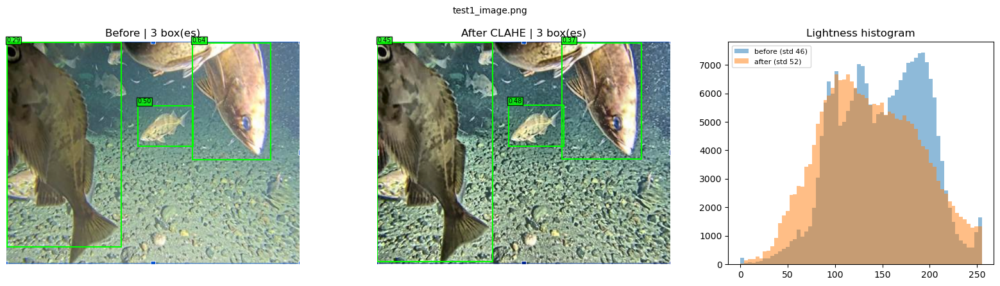

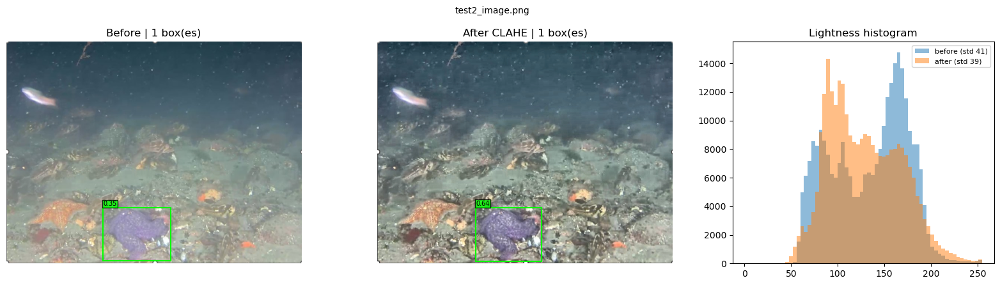

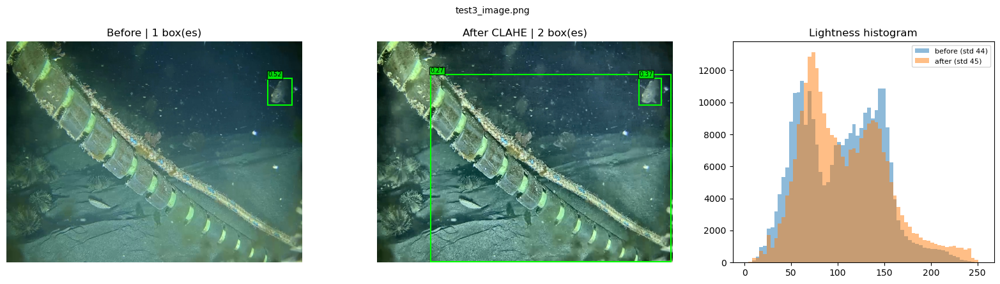

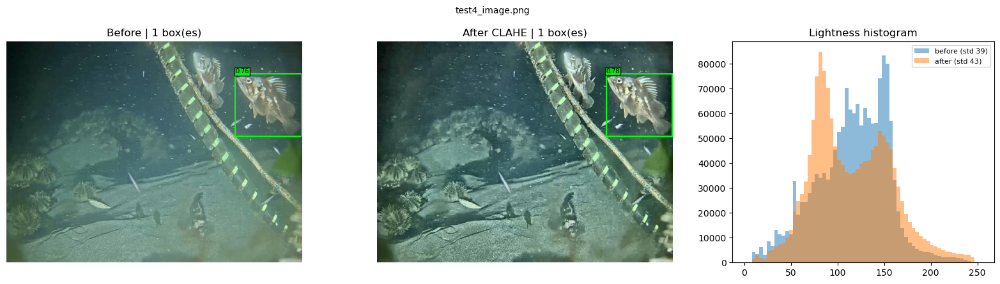

,image,boxes_before,boxes_after,max_conf_before,max_conf_after,contrast_before,contrast_after
0,test1_image.png,3,3,0.64,0.48,46.1,51.5
1,test2_image.png,1,1,0.35,0.64,40.7,38.7
2,test3_image.png,1,2,0.52,0.37,43.8,45.4
3,test4_image.png,1,1,0.76,0.78,38.8,42.8


Side-by-side images saved to /home/jovyan/vic02_work/compare


In [15]:
# Compare before vs after enhancement (CLAHE, the same function the detector uses)
# Run after cell 8 (needs clahe() and detect()).
img_dir = WORK / "my_images" / "rockfish"
paths = sorted(p for p in img_dir.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
print(f"Found {len(paths)} images in {img_dir.resolve()}")

RUN_DETECTOR = True        # also run the detector on both versions to see if CLAHE helps
save_dir = WORK / "compare"
save_dir.mkdir(parents=True, exist_ok=True)

def draw_boxes(ax, dets):
    for x1, y1, x2, y2, conf, *_ in dets:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", lw=1.5))
        ax.text(x1, max(0, y1 - 4), f"{conf:.2f}", color="black", fontsize=7,
                bbox=dict(facecolor="lime", alpha=0.8, pad=1))

summary = []
for p in paths:
    before = np.array(Image.open(p).convert("RGB"))
    after = clahe(before)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1, 0.8]})
    axes[0].imshow(before); axes[1].imshow(after)
    rec = dict(image=p.name)
    if RUN_DETECTOR:
        d_before, d_after = detect(before), detect(after)
        draw_boxes(axes[0], d_before); draw_boxes(axes[1], d_after)
        rec.update(boxes_before=len(d_before), boxes_after=len(d_after),
                   max_conf_before=round(max([d[4] for d in d_before], default=0), 2),
                   max_conf_after=round(max([d[4] for d in d_after], default=0), 2))
        axes[0].set_title(f"Before | {len(d_before)} box(es)")
        axes[1].set_title(f"After CLAHE | {len(d_after)} box(es)")
    else:
        axes[0].set_title("Before"); axes[1].set_title("After CLAHE")
    axes[0].axis("off"); axes[1].axis("off")

    # CLAHE only changes lightness (L in LAB), so compare the L-channel histograms
    L_before = cv2.cvtColor(before, cv2.COLOR_RGB2LAB)[..., 0].ravel()
    L_after = cv2.cvtColor(after, cv2.COLOR_RGB2LAB)[..., 0].ravel()
    axes[2].hist(L_before, bins=64, range=(0, 255), alpha=0.5, label=f"before (std {L_before.std():.0f})")
    axes[2].hist(L_after, bins=64, range=(0, 255), alpha=0.5, label=f"after (std {L_after.std():.0f})")
    axes[2].set_title("Lightness histogram"); axes[2].legend(fontsize=8)
    rec.update(contrast_before=round(L_before.std(), 1), contrast_after=round(L_after.std(), 1))

    fig.suptitle(p.name, fontsize=10)
    plt.tight_layout(); plt.show()

    # Save a side-by-side image (no boxes) for slides
    cv2.imwrite(str(save_dir / f"compare_{p.stem}.jpg"),
                cv2.cvtColor(np.hstack([before, after]), cv2.COLOR_RGB2BGR))
    summary.append(rec)

if summary:
    display(pd.DataFrame(summary))
    print("Side-by-side images saved to", save_dir.resolve())


In [16]:
import traceback

DETECTORS = {}

for name in DETECTOR_CHAIN:
    try:
        log(f"{name}: starting to load...")
        DETECTORS[name] = LOADERS[name]()
        log(f"{name}: ready")

    except Exception as ex:
        log(f"{name}: skipped ({type(ex).__name__}: {ex})")
        traceback.print_exc()

assert DETECTORS, "No detector could be loaded"

[22:19:07] cfd: starting to load...
[22:19:07] CFD: weights already downloaded (119 MB)
[22:19:07] CFD: loading onto the GPU ...
[22:19:07] cfd: ready
[22:19:07] sam3: starting to load...
[22:19:08] SAM 3: loading (first run downloads the weights) ...
[22:19:16] sam3: skipped (GatedRepoError: 401 Client Error. (Request ID: Root=1-6ad3f463-2162c2537f6c5b0271620c30;3021f547-2665-40c9-bbb1-9e32c8bf65d2)

Cannot access gated repo for url https://huggingface.co/facebook/sam3/resolve/main/config.json.
Access to model facebook/sam3 is restricted. You must have access to it and be authenticated to access it. Please log in.)
[22:19:16] mbari_315k: starting to load...
[22:19:16] Fallback: downloading weights from Hugging Face (FathomNet/MBARI-315k-yolov8) ...
[22:19:16] Fallback: loading YOLOv8 weights ...


Traceback (most recent call last):
  File "/srv/conda/envs/notebook/lib/python3.12/site-packages/huggingface_hub/utils/_errors.py", line 304, in hf_raise_for_status
    response.raise_for_status()
  File "/srv/conda/envs/notebook/lib/python3.12/site-packages/requests/models.py", line 1026, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 401 Client Error: Unauthorized for url: https://huggingface.co/facebook/sam3/resolve/main/config.json

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/tmp/ipykernel_3529/1244015209.py", line 8, in <module>
    DETECTORS[name] = LOADERS[name]()
                      ^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_3529/2613833327.py", line 53, in load_sam3
    proc = Sam3Processor(build_sam3_image_model())
                         ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/srv/conda/envs/notebook/lib/python3.12/site-packages/sam3/model_builder.py", line 6

[22:19:16] mbari_315k: ready


In [20]:
# 6) Load the detector (prints progress at every stage so a hang is easy to locate)
from tqdm.auto import tqdm

def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

def _download(url, dest, expected_size=None):
    # Writes to a .part file first, so an interrupted download is never mistaken for a finished one.
    tmp = dest.with_name(dest.name + ".part")
    # timeout=(connect, read): fail if the server stops sending data for 60 s, instead of hanging
    with requests.get(url, stream=True, timeout=(15, 60), headers=HEAD) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)) or expected_size
        with open(tmp, "wb") as fh, tqdm(total=total, unit="B", unit_scale=True, desc=dest.name) as bar:
            for chunk in r.iter_content(1 << 20):
                fh.write(chunk)
                bar.update(len(chunk))
    if expected_size and tmp.stat().st_size != expected_size:
        tmp.unlink()
        raise IOError(f"Incomplete download: got {tmp.stat().st_size if tmp.exists() else 0} of {expected_size} bytes")
    tmp.rename(dest)

def load_cfd():
    # Community Fish Detector (WildHackers): YOLOv12x, single class "fish", AGPL licence
    url = ("https://github.com/WildHackers/community-fish-detector/"
           "releases/download/cfd-1.00-yolov12x/cfd-yolov12x-1.00.pt")
    dest = WORK / "weights" / "cfd-yolov12x-1.00.pt"
    if dest.exists():
        log(f"CFD: weights already downloaded ({dest.stat().st_size / 1e6:.0f} MB)")
    else:
        log("CFD: downloading weights from GitHub ...")
        _download(url, dest)
    from ultralytics import YOLO
    log("CFD: loading onto the GPU ...")
    m = YOLO(str(dest))

    def detect(img_rgb):
        r = m.predict(Image.fromarray(img_rgb), conf=DET_CONF, imgsz=CFD_IMGSZ, device=0, verbose=False)[0]
        return [(float(x1), float(y1), float(x2), float(y2), float(c), "fish")
                for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy())]
    return detect

def load_sam3():
    # SAM 3 text-prompted detection. Weights are gated on Hugging Face (facebook/sam3).
    from huggingface_hub import get_token
    if not get_token():
        raise RuntimeError("not logged in to Hugging Face. Request access at "
                           "https://huggingface.co/facebook/sam3, then run "
                           "`from huggingface_hub import login; login()` and re-run this cell")
    log("SAM 3: loading (first run downloads the weights) ...")
    from sam3.model_builder import build_sam3_image_model
    from sam3.model.sam3_image_processor import Sam3Processor
    proc = Sam3Processor(build_sam3_image_model())

    def detect(img_rgb):
        h, w = img_rgb.shape[:2]
        with torch.no_grad():
            state = proc.set_image(Image.fromarray(img_rgb))
            out = proc.set_text_prompt(state=state, prompt=SAM3_PROMPT)
        boxes = torch.as_tensor(out["boxes"]).float().cpu().numpy().reshape(-1, 4)
        scores = torch.as_tensor(out["scores"]).float().cpu().numpy().reshape(-1)
        if len(boxes) and boxes.max() <= 1.0:          # normalised coordinates -> pixels
            boxes = boxes * np.array([w, h, w, h])
        return [(float(x1), float(y1), float(x2), float(y2), float(c), SAM3_PROMPT)
                for (x1, y1, x2, y2), c in zip(boxes, scores) if c >= DET_CONF]
    return detect

def load_mbari_315k():
    from huggingface_hub import list_repo_files, hf_hub_download
    repo = "FathomNet/MBARI-315k-yolov8"
    log(f"Fallback: downloading weights from Hugging Face ({repo}) ...")
    pt = [f for f in list_repo_files(repo) if f.endswith(".pt")][0]
    path = hf_hub_download(repo, pt)
    log("Fallback: loading YOLOv8 weights ...")
    from ultralytics import YOLO
    m = YOLO(path)

    def detect(img_rgb):
        r = m.predict(Image.fromarray(img_rgb), conf=DET_CONF, device=0, verbose=False)[0]
        out = []
        for (x1, y1, x2, y2), conf, c in zip(r.boxes.xyxy.cpu().numpy(),
                                              r.boxes.conf.cpu().numpy(),
                                              r.boxes.cls.cpu().numpy()):
            out.append((float(x1), float(y1), float(x2), float(y2), float(conf), r.names[int(c)]))
        return out
    return detect

LOADERS = {"cfd": load_cfd, "sam3": load_sam3, "mbari_315k": load_mbari_315k}
DETECTORS = {}
for name in DETECTOR_CHAIN:
    try:
        DETECTORS[name] = LOADERS[name]()
        log(f"{name}: ready")
    except Exception as ex:
        log(f"{name}: skipped ({type(ex).__name__}: {ex})")
assert DETECTORS, "No detector could be loaded"
DETECTOR_NAME = " -> ".join(DETECTORS)

def detect(img_rgb):
    # Try each detector in order; stop at the first one that finds something.
    for name, fn in DETECTORS.items():
        dets = fn(img_rgb)
        if dets:
            return [d + (name,) for d in dets]
    return []

log(f"Detector chain: {DETECTOR_NAME}")

[22:22:09] CFD: weights already downloaded (119 MB)
[22:22:09] CFD: loading onto the GPU ...
[22:22:09] cfd: ready
[22:22:09] SAM 3: loading (first run downloads the weights) ...
[22:22:18] sam3: skipped (GatedRepoError: 401 Client Error. (Request ID: Root=1-6ad3f51a-134edc9f1977f5fa2838a832;71c30f7c-c055-4ee4-9849-acad12c2a2fa)

Cannot access gated repo for url https://huggingface.co/facebook/sam3/resolve/main/config.json.
Access to model facebook/sam3 is restricted. You must have access to it and be authenticated to access it. Please log in.)
[22:22:18] Fallback: downloading weights from Hugging Face (FathomNet/MBARI-315k-yolov8) ...
[22:22:18] Fallback: loading YOLOv8 weights ...
[22:22:19] mbari_315k: ready
[22:22:19] Detector chain: cfd -> mbari_315k


In [21]:
# 7) Load BioCLIP and precompute text embeddings for the candidate list
import open_clip

clip_model = None
for name in BIOCLIP_MODELS:
    try:
        clip_model, _, clip_pre = open_clip.create_model_and_transforms(name)
        tokenizer = open_clip.get_tokenizer(name)
        BIOCLIP_NAME = name
        break
    except Exception as ex:
        print(f"[{name} failed to load] {ex}")
assert clip_model is not None, "All BioCLIP models failed to load"
clip_model = clip_model.to(DEVICE).eval()

with torch.no_grad(), torch.autocast("cuda"):
    TEXT_FEATS = clip_model.encode_text(tokenizer(PROMPTS).to(DEVICE))
TEXT_FEATS = F.normalize(TEXT_FEATS.float(), dim=-1)
LOGIT_SCALE = clip_model.logit_scale.exp().item()
print("Classifier:", BIOCLIP_NAME, "| GPU memory used: %.1f GB" % (torch.cuda.memory_allocated() / 1e9))

Classifier: hf-hub:imageomics/bioclip-2.5-vith14 | GPU memory used: 4.0 GB


In [22]:
# 8) Pipeline step functions
def clahe(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def crop(img_rgb, box):
    h, w = img_rgb.shape[:2]
    x1, y1, x2, y2 = box[:4]
    px, py = (x2 - x1) * CROP_PAD, (y2 - y1) * CROP_PAD
    x1, y1 = max(0, int(x1 - px)), max(0, int(y1 - py))
    x2, y2 = min(w, int(x2 + px)), min(h, int(y2 + py))
    return Image.fromarray(img_rgb[y1:y2, x1:x2])

def classify(pil_images):
    x = torch.stack([clip_pre(im) for im in pil_images]).to(DEVICE)
    with torch.no_grad(), torch.autocast("cuda"):
        f = clip_model.encode_image(x)
    f = F.normalize(f.float(), dim=-1)
    return (LOGIT_SCALE * f @ TEXT_FEATS.T).softmax(-1).cpu().numpy()

def lowest_clade(prob):
    # Walk up from species, summing child probabilities at each rank;
    # the first rank whose best taxon reaches CLADE_T is the lowest confident clade.
    for rank in reversed(RANKS):
        agg = {}
        for t, p in zip(TAXA, prob):
            agg[t[rank]] = agg.get(t[rank], 0.0) + float(p)
        name, p = max(agg.items(), key=lambda kv: kv[1])
        if p >= CLADE_T:
            return rank, name, p
    return None, None, 0.0

def decide_status(det_conf, rank):
    if det_conf is not None and det_conf < DET_REVIEW_CONF:
        return "Needs review"
    if rank == "species":
        return "Identified"
    if rank in ("genus", "family"):
        return "Uncertain"
    return "Needs review"

def top_k(prob, k=3):
    idx = np.argsort(-prob)[:k]
    return "; ".join(f"{TAXA[i]['common']} {prob[i]:.2f}" for i in idx)

def consistent_with_truth(truth, rank, name):
    # Does the predicted lowest clade agree with the true label? (None if truth is not in the candidate list)
    if truth not in LINEAGE or rank is None:
        return None
    return LINEAGE[truth][rank] == name

In [23]:
# 9) Full pipeline for one image + visualisation
STATUS_COLOR = {"Identified": "lime", "Uncertain": "gold",
                "Needs review": "orangered", "No detection": "gray"}

def run_image(row):
    img = np.array(Image.open(row["path"]).convert("RGB"))
    t0 = time.time()
    dets = detect(clahe(img) if USE_CLAHE else img)
    dets = sorted(dets, key=lambda d: -d[4])[:MAX_DETS]
    recs = []
    if not dets:
        # Diagnostic only: classify the whole image, but the status stays No detection
        prob = classify([Image.fromarray(img)])[0]
        rank, name, p = lowest_clade(prob)
        recs.append(dict(status="No detection", det_label=None, det_conf=None,
                         clade_rank=None, clade=None, clade_prob=None,
                         top3=None, whole_image_diag=f"{name} ({rank}, {p:.2f}) | {top_k(prob)}",
                         box=None, det_source=None))
    else:
        probs = classify([crop(img, d) for d in dets])
        for d, prob in zip(dets, probs):
            rank, name, p = lowest_clade(prob)
            recs.append(dict(status=decide_status(d[4], rank), det_label=d[5], det_conf=round(d[4], 2),
                             clade_rank=rank, clade=name, clade_prob=round(p, 2),
                             top3=top_k(prob), whole_image_diag=None, box=d[:4], det_source=d[6]))
    torch.cuda.synchronize()
    elapsed = time.time() - t0
    for r in recs:
        r.update(image=Path(row["path"]).name, truth=row["truth"], seconds=round(elapsed, 2),
                 matches_truth=consistent_with_truth(row["truth"], r["clade_rank"], r["clade"]))
    return img, recs

def show(img, recs, title):
    fig, ax = plt.subplots(figsize=(7, 7 * img.shape[0] / img.shape[1]))
    ax.imshow(img); ax.set_axis_off(); ax.set_title(title, fontsize=10)
    for r in recs:
        if r["box"] is None:
            ax.text(10, 30, "No detection", color="white", fontsize=11,
                    bbox=dict(facecolor="gray", alpha=0.8))
            continue
        x1, y1, x2, y2 = r["box"]; c = STATUS_COLOR[r["status"]]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=c, lw=2))
        label = f"{r['status']}: {r['clade'] or '?'} ({r['clade_rank'] or '-'}, {r['clade_prob']})"
        ax.text(x1, max(0, y1 - 6), label, color="black", fontsize=8,
                bbox=dict(facecolor=c, alpha=0.85, pad=1))
    plt.show()

COLS = ["image", "truth", "status", "clade_rank", "clade", "clade_prob",
        "matches_truth", "det_source", "det_conf", "top3", "whole_image_diag", "seconds"]

def run_test(test_name, inat_taxon):
    rows = collect_images(test_name, inat_taxon)
    all_recs = []
    for row in rows:
        img, recs = run_image(row)
        show(img, recs, f"{test_name} | truth: {row['truth']}")
        for r in recs:
            r["test"] = test_name
        all_recs += recs
    df = pd.DataFrame(all_recs)
    if len(df):
        display(df[COLS])
    return df

## Test: rockfish (*Sebastes*)

Images come from two sources: the team's ONC images in `vic02_work/my_images/rockfish/` (truth shown as "(ONC image)") and iNaturalist photos of genus *Sebastes*.

The true iNaturalist species may not be in the candidate list (then `matches_truth` is None). This is a good test of the taxonomy logic: if rockfish species cannot be separated, the ideal output stops at genus *Sebastes* with status Uncertain.

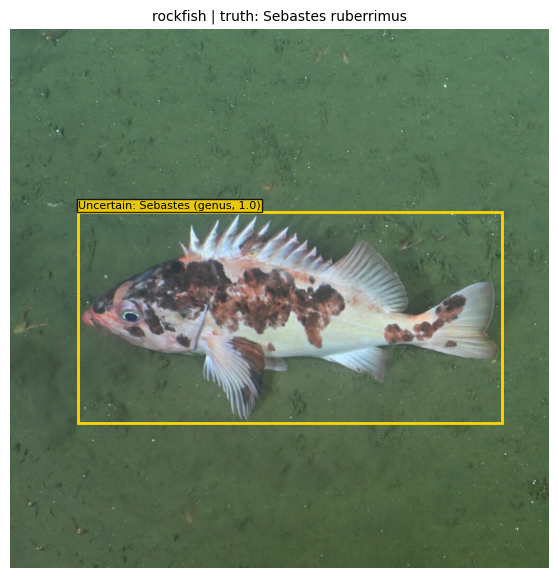

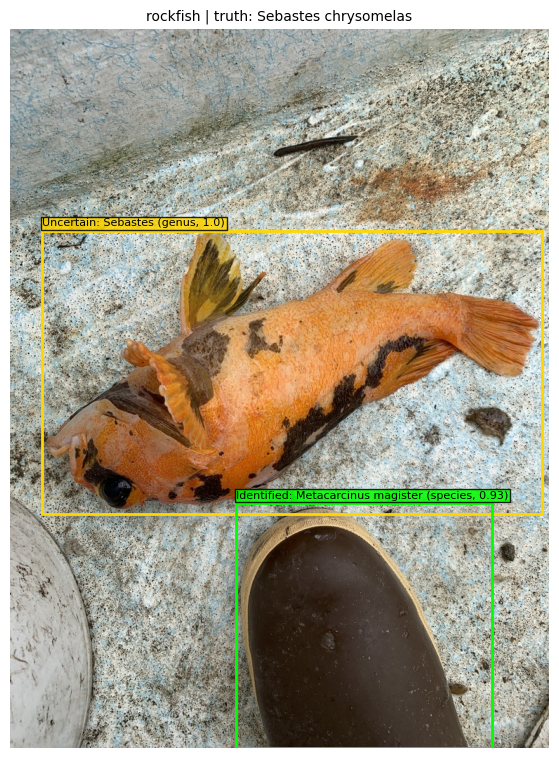

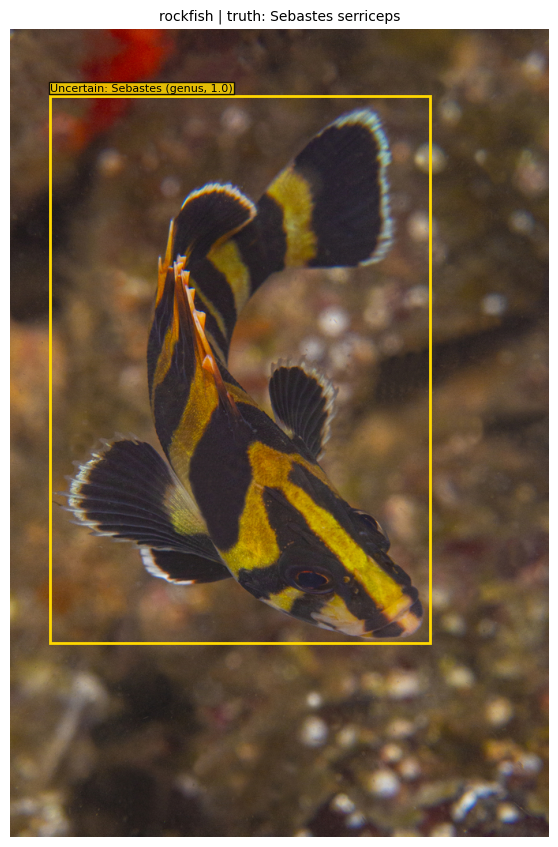

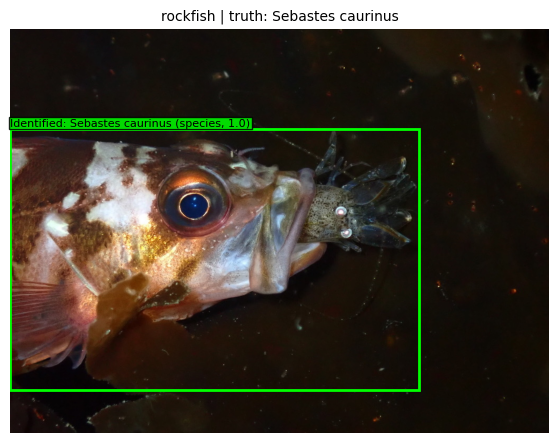

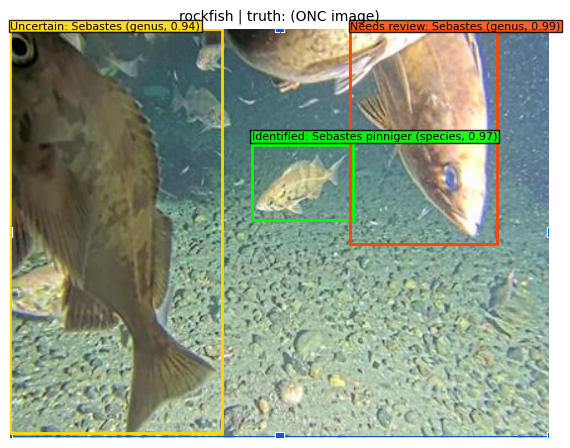

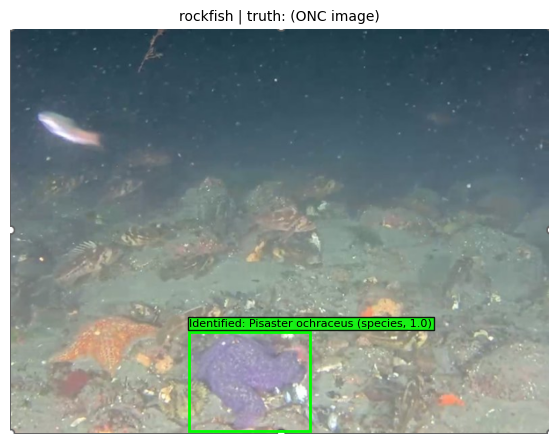

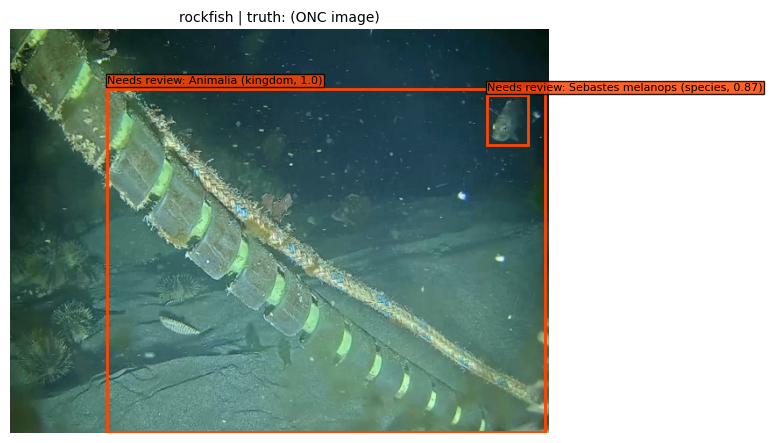

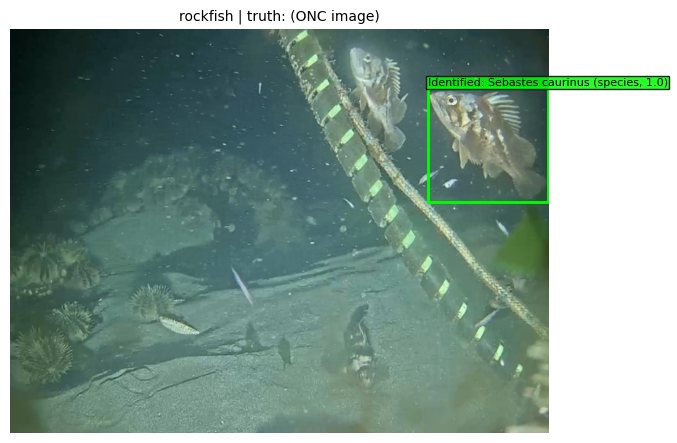

,image,truth,status,clade_rank,clade,clade_prob,matches_truth,det_source,det_conf,top3,whole_image_diag,seconds
0,inat_330106081.jpg,Sebastes ruberrimus,Uncertain,genus,Sebastes,1.00,True,cfd,0.93,copper rockfish 0.77; yelloweye rockfish 0.22;...,None,4.32
1,inat_90909844.jpg,Sebastes chrysomelas,Uncertain,genus,Sebastes,1.00,None,cfd,0.91,China rockfish 0.79; copper rockfish 0.19; can...,None,3.69
2,inat_90909844.jpg,Sebastes chrysomelas,Identified,species,Metacarcinus magister,0.93,None,cfd,0.58,Dungeness crab 0.93; kelp greenling 0.06; cabe...,None,3.69
3,inat_59394191.jpg,Sebastes serriceps,Uncertain,genus,Sebastes,1.00,None,cfd,0.86,China rockfish 0.60; yelloweye rockfish 0.40; ...,None,3.36
4,inat_72243727.jpg,Sebastes caurinus,Identified,species,Sebastes caurinus,1.00,True,cfd,0.90,copper rockfish 1.00; quillback rockfish 0.00;...,None,0.23
5,test1_image.png,(ONC image),Identified,species,Sebastes pinniger,0.97,None,cfd,0.48,canary rockfish 0.97; yelloweye rockfish 0.03;...,None,0.49
6,test1_image.png,(ONC image),Uncertain,genus,Sebastes,0.94,None,cfd,0.45,black rockfish 0.33; copper rockfish 0.28; yel...,None,0.49
7,test1_image.png,(ONC image),Needs review,genus,Sebastes,0.99,None,cfd,0.37,canary rockfish 0.80; yelloweye rockfish 0.15;...,None,0.49
8,test2_image.png,(ONC image),Identified,species,Pisaster ochraceus,1.00,None,cfd,0.64,ochre sea star 1.00; California sea cucumber 0...,None,0.20
9,test3_image.png,(ONC image),Needs review,species,Sebastes melanops,0.87,None,cfd,0.37,black rockfish 0.87; copper rockfish 0.09; qui...,None,0.40


In [24]:
df_rock = run_test("rockfish", "Sebastes")

Image size: 545 x 414 px | 3 box(es) | 0.51 s


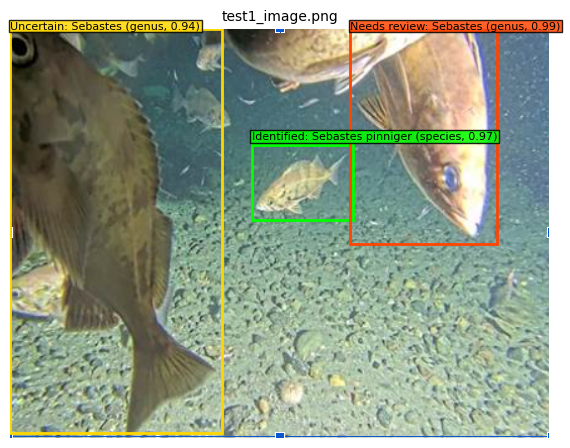

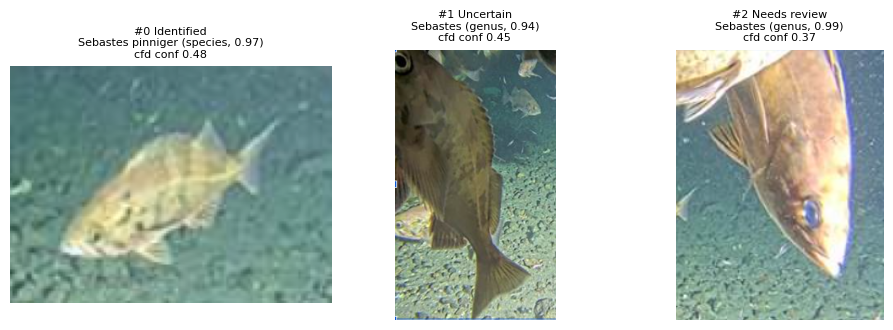

,image,truth,status,clade_rank,clade,clade_prob,matches_truth,det_source,det_conf,top3,whole_image_diag,seconds
0,test1_image.png,(ONC image),Identified,species,Sebastes pinniger,0.97,None,cfd,0.48,canary rockfish 0.97; yelloweye rockfish 0.03;...,None,0.51
1,test1_image.png,(ONC image),Uncertain,genus,Sebastes,0.94,None,cfd,0.45,black rockfish 0.33; copper rockfish 0.28; yel...,None,0.51
2,test1_image.png,(ONC image),Needs review,genus,Sebastes,0.99,None,cfd,0.37,canary rockfish 0.80; yelloweye rockfish 0.15;...,None,0.51


In [26]:
# Test a single ONC image
TEST_FILE = "test1_image.png"
test_path = WORK / "my_images" / "rockfish" / TEST_FILE
assert test_path.exists(), f"Image not found. Upload it to: {test_path.resolve()}"

MAX_DETS = 20   # this frame has many fish; allow more boxes than the default 10

row = dict(path=str(test_path), truth="(ONC image)", source="local")
img, recs = run_image(row)
print(f"Image size: {img.shape[1]} x {img.shape[0]} px | {len(recs)} box(es) | {recs[0]['seconds']} s")

# 1) Full frame with boxes
show(img, recs, TEST_FILE)

# 2) Each crop on its own, so you can see exactly what BioCLIP was given
boxed = [r for r in recs if r["box"] is not None]
if boxed:
    n = len(boxed)
    cols = min(4, n)
    rows_ = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows_, cols, figsize=(3.2 * cols, 3.4 * rows_), squeeze=False)
    for ax in axes.flat:
        ax.set_axis_off()
    for i, (ax, r) in enumerate(zip(axes.flat, boxed)):
        ax.imshow(crop(img, r["box"]))
        ax.set_title(f"#{i} {r['status']}\n{r['clade']} ({r['clade_rank']}, {r['clade_prob']})\n"
                     f"{r['det_source']} conf {r['det_conf']}", fontsize=8)
    plt.tight_layout()
    plt.show()

# 3) Results table
df_test1 = pd.DataFrame(recs)
display(df_test1[COLS])

Image size: 613 x 461 px | 1 box(es) | 0.26 s


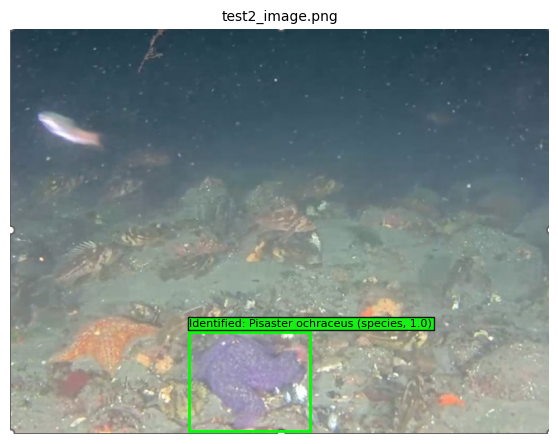

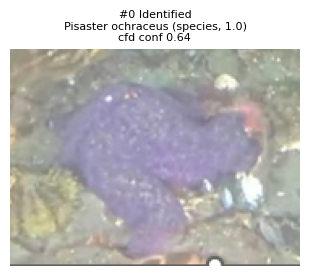

,image,truth,status,clade_rank,clade,clade_prob,matches_truth,det_source,det_conf,top3,whole_image_diag,seconds
0,test2_image.png,(ONC image),Identified,species,Pisaster ochraceus,1.0,None,cfd,0.64,ochre sea star 1.00; California sea cucumber 0...,None,0.26


In [27]:
# Test a single ONC image
TEST_FILE = "test2_image.png"
test_path = WORK / "my_images" / "rockfish" / TEST_FILE
assert test_path.exists(), f"Image not found. Upload it to: {test_path.resolve()}"

MAX_DETS = 20   # this frame has many fish; allow more boxes than the default 10

row = dict(path=str(test_path), truth="(ONC image)", source="local")
img, recs = run_image(row)
print(f"Image size: {img.shape[1]} x {img.shape[0]} px | {len(recs)} box(es) | {recs[0]['seconds']} s")

# 1) Full frame with boxes
show(img, recs, TEST_FILE)

# 2) Each crop on its own, so you can see exactly what BioCLIP was given
boxed = [r for r in recs if r["box"] is not None]
if boxed:
    n = len(boxed)
    cols = min(4, n)
    rows_ = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows_, cols, figsize=(3.2 * cols, 3.4 * rows_), squeeze=False)
    for ax in axes.flat:
        ax.set_axis_off()
    for i, (ax, r) in enumerate(zip(axes.flat, boxed)):
        ax.imshow(crop(img, r["box"]))
        ax.set_title(f"#{i} {r['status']}\n{r['clade']} ({r['clade_rank']}, {r['clade_prob']})\n"
                     f"{r['det_source']} conf {r['det_conf']}", fontsize=8)
    plt.tight_layout()
    plt.show()

# 3) Results table
df_test1 = pd.DataFrame(recs)
display(df_test1[COLS])

Image size: 615 x 461 px | 2 box(es) | 0.5 s


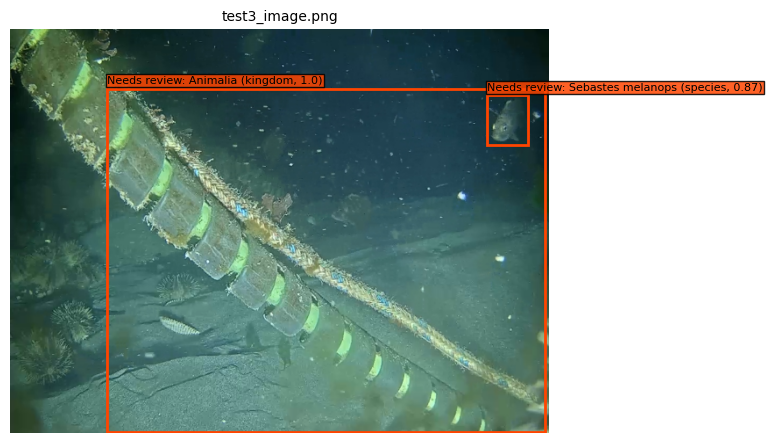

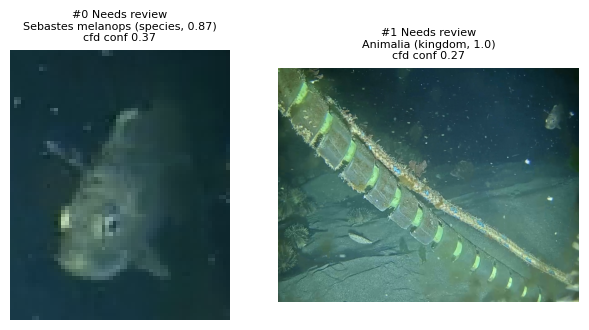

,image,truth,status,clade_rank,clade,clade_prob,matches_truth,det_source,det_conf,top3,whole_image_diag,seconds
0,test3_image.png,(ONC image),Needs review,species,Sebastes melanops,0.87,None,cfd,0.37,black rockfish 0.87; copper rockfish 0.09; qui...,None,0.5
1,test3_image.png,(ONC image),Needs review,kingdom,Animalia,1.00,None,cfd,0.27,yelloweye rockfish 0.54; California sea cucumb...,None,0.5


In [28]:
# Test a single ONC image
TEST_FILE = "test3_image.png"
test_path = WORK / "my_images" / "rockfish" / TEST_FILE
assert test_path.exists(), f"Image not found. Upload it to: {test_path.resolve()}"

MAX_DETS = 20   # this frame has many fish; allow more boxes than the default 10

row = dict(path=str(test_path), truth="(ONC image)", source="local")
img, recs = run_image(row)
print(f"Image size: {img.shape[1]} x {img.shape[0]} px | {len(recs)} box(es) | {recs[0]['seconds']} s")

# 1) Full frame with boxes
show(img, recs, TEST_FILE)

# 2) Each crop on its own, so you can see exactly what BioCLIP was given
boxed = [r for r in recs if r["box"] is not None]
if boxed:
    n = len(boxed)
    cols = min(4, n)
    rows_ = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows_, cols, figsize=(3.2 * cols, 3.4 * rows_), squeeze=False)
    for ax in axes.flat:
        ax.set_axis_off()
    for i, (ax, r) in enumerate(zip(axes.flat, boxed)):
        ax.imshow(crop(img, r["box"]))
        ax.set_title(f"#{i} {r['status']}\n{r['clade']} ({r['clade_rank']}, {r['clade_prob']})\n"
                     f"{r['det_source']} conf {r['det_conf']}", fontsize=8)
    plt.tight_layout()
    plt.show()

# 3) Results table
df_test1 = pd.DataFrame(recs)
display(df_test1[COLS])

Image size: 1440 x 1080 px | 1 box(es) | 0.31 s


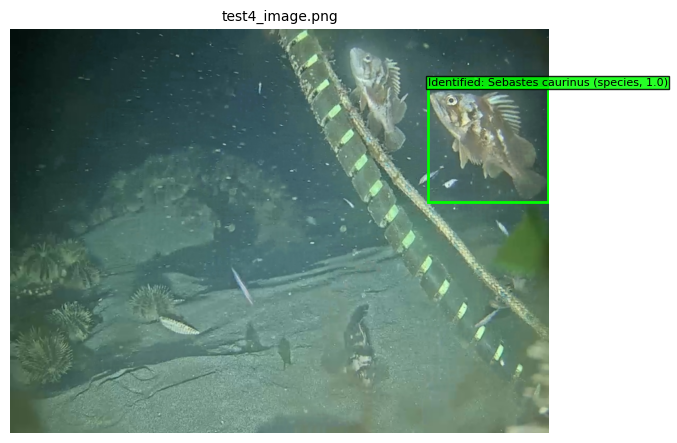

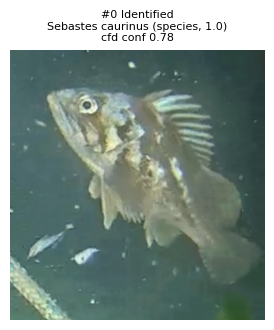

,image,truth,status,clade_rank,clade,clade_prob,matches_truth,det_source,det_conf,top3,whole_image_diag,seconds
0,test4_image.png,(ONC image),Identified,species,Sebastes caurinus,1.0,None,cfd,0.78,copper rockfish 1.00; quillback rockfish 0.00;...,None,0.31


In [29]:
# Test a single ONC image
TEST_FILE = "test4_image.png"
test_path = WORK / "my_images" / "rockfish" / TEST_FILE
assert test_path.exists(), f"Image not found. Upload it to: {test_path.resolve()}"

MAX_DETS = 20   # this frame has many fish; allow more boxes than the default 10

row = dict(path=str(test_path), truth="(ONC image)", source="local")
img, recs = run_image(row)
print(f"Image size: {img.shape[1]} x {img.shape[0]} px | {len(recs)} box(es) | {recs[0]['seconds']} s")

# 1) Full frame with boxes
show(img, recs, TEST_FILE)

# 2) Each crop on its own, so you can see exactly what BioCLIP was given
boxed = [r for r in recs if r["box"] is not None]
if boxed:
    n = len(boxed)
    cols = min(4, n)
    rows_ = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows_, cols, figsize=(3.2 * cols, 3.4 * rows_), squeeze=False)
    for ax in axes.flat:
        ax.set_axis_off()
    for i, (ax, r) in enumerate(zip(axes.flat, boxed)):
        ax.imshow(crop(img, r["box"]))
        ax.set_title(f"#{i} {r['status']}\n{r['clade']} ({r['clade_rank']}, {r['clade_prob']})\n"
                     f"{r['det_source']} conf {r['det_conf']}", fontsize=8)
    plt.tight_layout()
    plt.show()

# 3) Results table
df_test1 = pd.DataFrame(recs)
display(df_test1[COLS])

In [30]:
# 10) Summary
df_all = df_rock.copy()
print("Detector:", DETECTOR_NAME, "| Classifier:", BIOCLIP_NAME, "\n")
print(df_all.groupby(["test", "status"]).size().unstack(fill_value=0), "\n")
print("Boxes per detector:\n", df_all["det_source"].value_counts(dropna=False), "\n")
judged = df_all[df_all["matches_truth"].notna()]
if len(judged):
    print("Lowest clade agrees with true label: %d / %d" % (judged["matches_truth"].sum(), len(judged)))
print("Mean time per image: %.2f s" % df_all.groupby("image")["seconds"].first().mean())
df_all.drop(columns=["box"]).to_csv(WORK / "results.csv", index=False)
print("Results saved to", WORK / "results.csv")

Detector: cfd -> mbari_315k | Classifier: hf-hub:imageomics/bioclip-2.5-vith14 

status    Identified  Needs review  Uncertain
test                                         
rockfish           5             3          4 

Boxes per detector:
 det_source
cfd    12
Name: count, dtype: int64 

Lowest clade agrees with true label: 2 / 2
Mean time per image: 1.61 s
Results saved to /home/jovyan/vic02_work/results.csv


## Reading the results

- **Many No detection results**: none of the three detectors found a fish. On murky ONC frames this is a useful finding in itself. The `det_source` column shows how often the backups (SAM 3, MBARI 315k) were needed. Check the `whole_image_diag` column to tell whether the problem is detection or classification.
- **Uncertain at genus *Sebastes***: the taxonomy logic is working. This is better than confidently reporting the wrong species.
- **Thornyheads (*Sebastolobus*)**: same family as rockfish. If ONC images stop at family Sebastidae, the model cannot separate rockfish from thornyheads.
- **Probabilities are not calibrated confidence**: they change when the candidate list gets longer or shorter. Final thresholds should be set on the data team's labelled validation set.
- **Adapting to the ONC site**: replace `CANDIDATES` with the species actually expected at the camera location.